# Scriptor: report figures and numbers, regenerated from code

Every graph and number in the project report is produced here by running the project's own code.
Nothing below is typed in by hand except the values **as printed in the report**, which are shown
next to the freshly measured values for comparison.

Run from the repository root: `Kernel -> Restart & Run All`. Outputs go to `out/report_proof/`.

In [1]:
import json, subprocess, sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
OUT = ROOT / "out" / "report_proof"
OUT.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

from engine.models import Style
from engine.paths import order_paths, rdp, toolpath_stats
from engine.pipeline import generate_strokes, make_gcode
from engine.planner import PageSpec

print("repository:", ROOT)
print("python", sys.version.split()[0], "| numpy", np.__version__)

repository: D:\minor\scriptor
python 3.13.13 | numpy 2.5.5


## Figure 3.1: handwritten lab-record pages collected as writer samples

The photos in `docs/samples/` (phone photos of the team's lab record).

10 photos


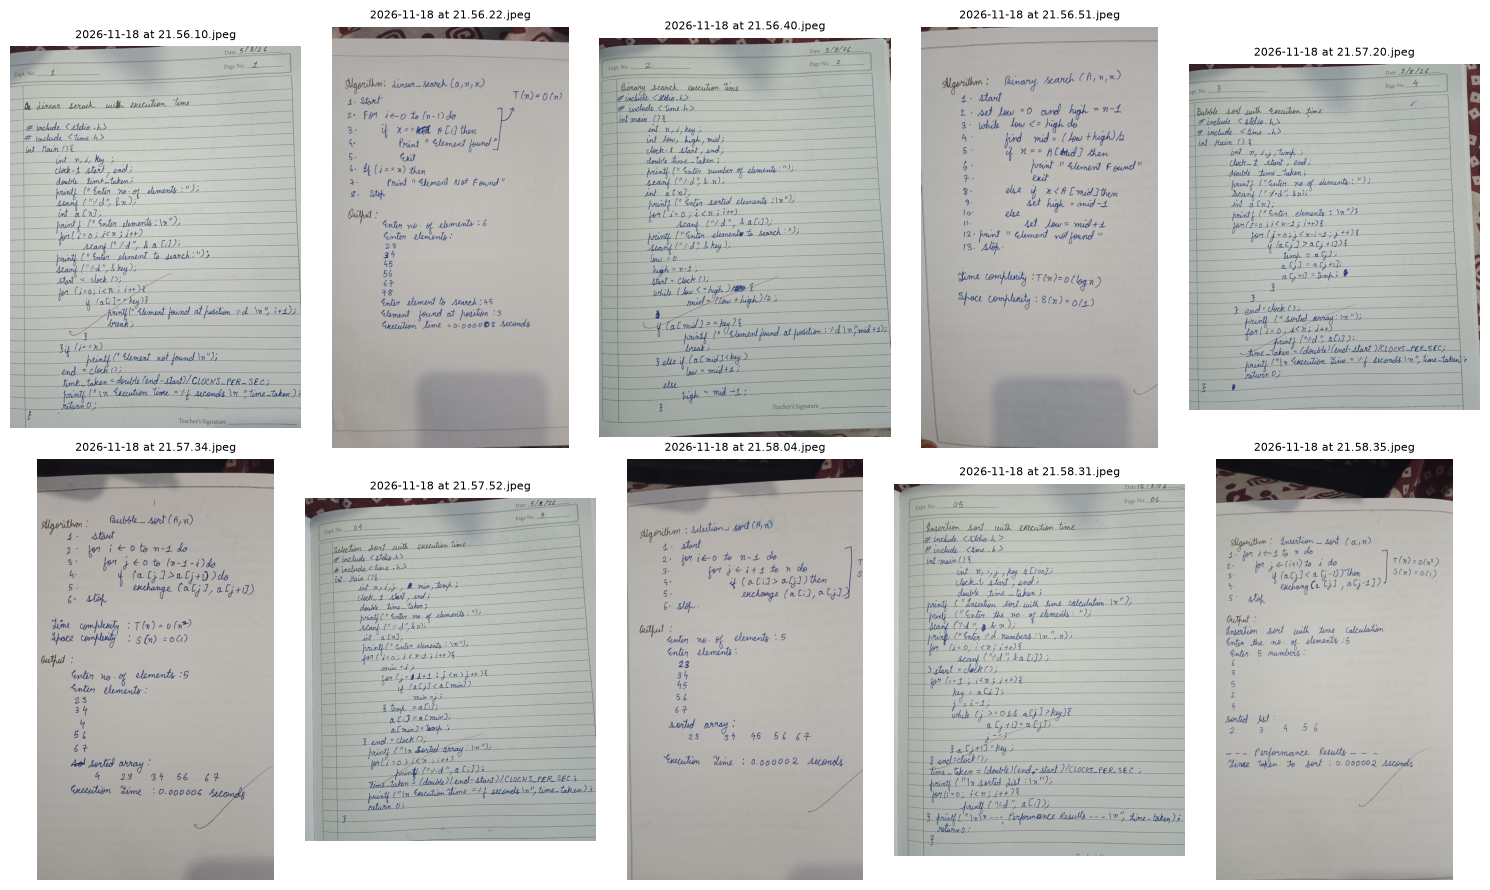

In [2]:
from PIL import Image as PILImage, ImageOps

photos = sorted((ROOT / "docs" / "samples").glob("*.jpeg"))
print(len(photos), "photos")
fig, axes = plt.subplots(2, 5, figsize=(15, 9))
for ax, p in zip(axes.flat, photos):
    ax.imshow(ImageOps.exif_transpose(PILImage.open(p)))
    ax.set_title(p.name.replace("WhatsApp Image ", ""), fontsize=8)
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "fig3_1_samples.png", dpi=110)
plt.show()

## Figure 4.1: toolpath of the linear search page

The linear search program (`examples/linear-search-program.txt`) written by the font model
(bias 1, seed 7, default page), then joined, simplified (RDP) and ordered (nearest neighbour).
Blue = pen down, dashed red = pen-up travel.

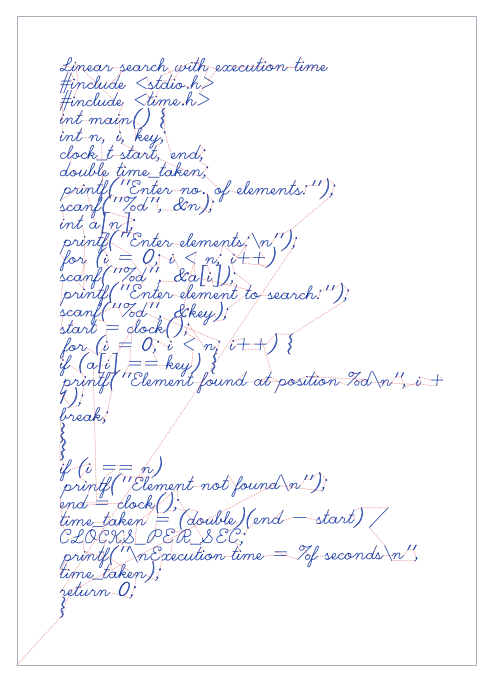

{
 "paths": 835,
 "draw_mm": 7023.222,
 "travel_mm": 3203.662,
 "draw_s": 140.464,
 "travel_s": 38.444,
 "pen_s": 208.75,
 "total_s": 387.658,
 "pen_share": 0.538,
 "travel_mm_written_order": 5822.591,
 "total_s_written_order": 419.086,
 "paths_before_join": 999,
 "points": 7205,
 "gcode_lines": 10552
}

First lines of the G-code:
; scriptor job=report page=1/1
G21 ; mm
G90 ; absolute
M5 ; pen up
G0 X0 Y0
G0 X20.00 Y21.95 F5000
M3 S90 ; pen down
G4 P0.15
G1 X20.96 Y22.48 F3000
G1 X21.31 Y23.09 F3000
G1 X21.36 Y23.71 F3000
G1 X20.66 Y25.37 F3000
G1 X20.72 Y25.75 F3000
G1 X21.41 Y26.37 F3000
... 10,552 lines in total (the report quotes 10,019 for its version of this page)


212351

In [3]:
BLUE, RED, ORANGE, GREY = "#1d3fa8", "#d33b3b", "#f08a4b", "#9aa3b2"
spec = PageSpec()
program = (ROOT / "examples" / "linear-search-program.txt").read_text(encoding="utf-8")
page = generate_strokes(program, Style(), "font", 1.0, 7, spec)[0]
res = make_gcode([p.round(3) for p in page.paths], spec.height, "job=report page=1/1")

def draw_toolpath(paths, ax, home=(0.0, spec.height)):
    ax.add_patch(plt.Rectangle((0, 0), spec.width, spec.height, fill=False, ec=GREY, lw=0.6))
    cur = home
    for p in paths:
        ax.plot([cur[0], p[0][0]], [cur[1], p[0][1]], color=RED, lw=0.35, ls=(0, (3, 2)), alpha=0.8)
        ax.plot(p[:, 0], p[:, 1], color=BLUE, lw=0.55)
        cur = p[-1]
    ax.set_xlim(-3, spec.width + 3); ax.set_ylim(spec.height + 3, -3); ax.set_aspect("equal"); ax.axis("off")

fig, ax = plt.subplots(figsize=(6.2, 8.6))
draw_toolpath(res.paths, ax)
fig.savefig(OUT / "fig4_1_toolpath.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print(json.dumps(res.stats, indent=1))
print("\nFirst lines of the G-code:")
print("\n".join(res.gcode.splitlines()[:14]))
print(f"... {res.stats['gcode_lines']:,} lines in total (the report quotes 10,019 for its version of this page)")
(OUT / "linear_search_page.gcode").write_text(res.gcode)

## Figure 5.1 and Table 5.2: pen-up travel and plot time for the prototype page

`docs/make_figures.py` (the script that made the report's figure) is run here with its output
redirected to `out/report_proof/`, so the committed figure is not overwritten.

written  paths  547  ink    4629 mm  travel   3046 mm  time 265.9 s (draw 93, travel 37, pen 137, 51%)  lines 6926
ordered  paths  547  ink    4629 mm  travel   1987 mm  time 253.2 s (draw 93, travel 24, pen 137, 54%)  lines 6926
joined   paths  410  ink    4635 mm  travel   2031 mm  time 219.6 s (draw 93, travel 24, pen 102, 47%)  lines 6230


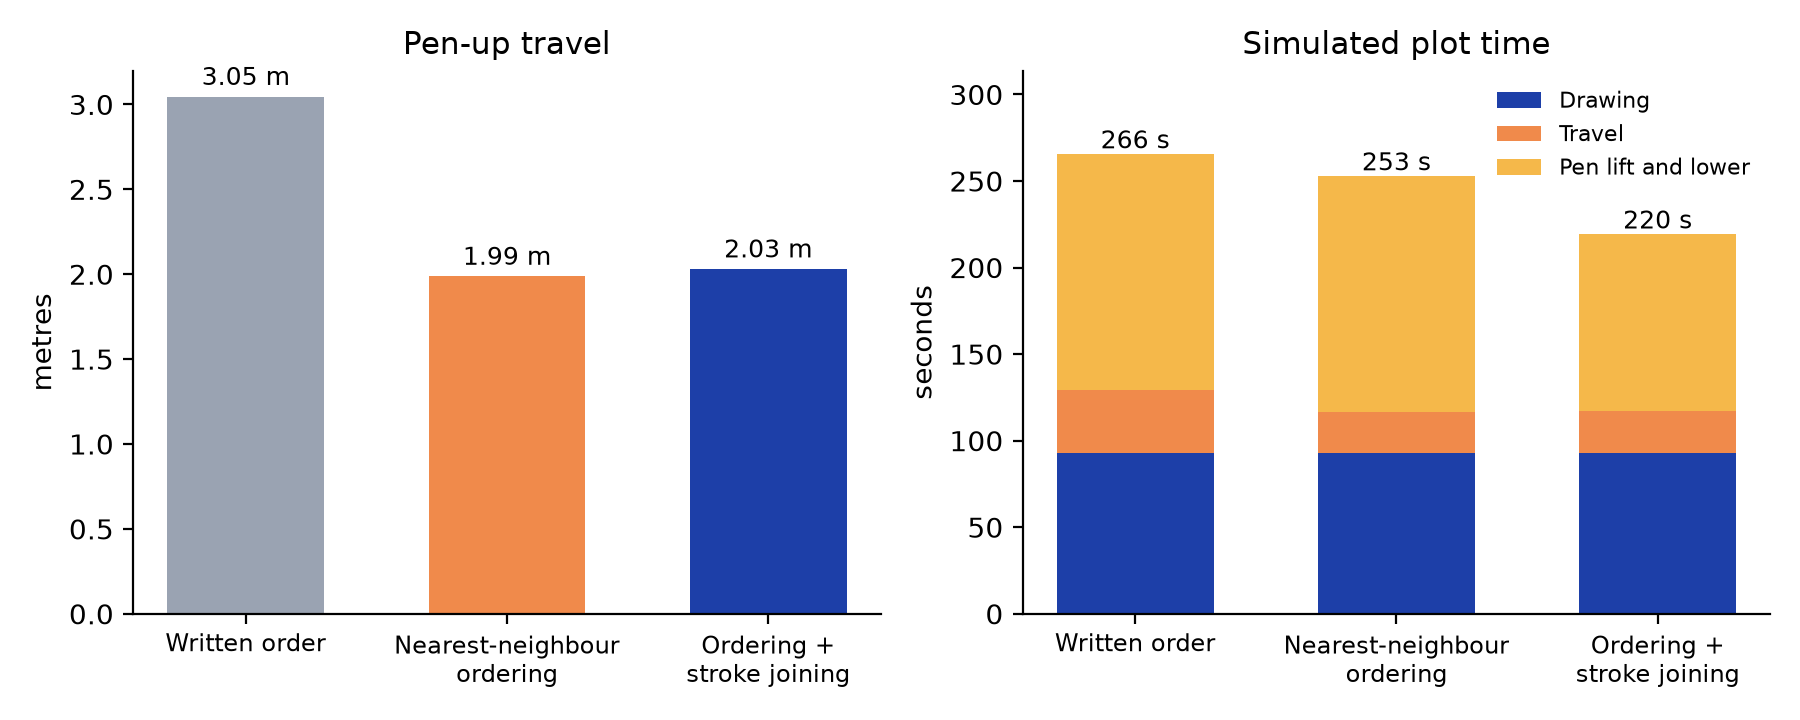

In [4]:
sys.path.insert(0, str(ROOT / "docs"))
import make_figures
make_figures.OUT = OUT
make_figures.main()
display(Image(str(OUT / "fig09-ordering.png"), width=900))

In [5]:
n = json.loads((OUT / "prototype-page.json").read_text())
w, o, j = n["written"], n["ordered"], n["joined"]
rows = [
    ("Pen paths after joining", "410", f"{j['paths']}"),
    ("Pen paths before joining", "547", f"{w['paths']}"),
    ("Drawn ink length (mm)", "4,635", f"{j['draw_mm']:,.0f}"),
    ("Pen-up travel, written order (mm)", "3,046", f"{w['travel_mm']:,.0f}"),
    ("Pen-up travel, after ordering (mm)", "1,987", f"{o['travel_mm']:,.0f}"),
    ("Travel saved by ordering", "35%", f"{100 * (1 - o['travel_mm'] / w['travel_mm']):.0f}%"),
    ("Pen-up travel, ordering + joining (mm)", "2,031", f"{j['travel_mm']:,.0f}"),
    ("G-code lines", "6,230", f"{j['gcode_lines']:,}"),
    ("Plot time, ordered + joined (s)", "220", f"{j['total_s']:.0f}"),
    ("Plot time, written order (s)", "266", f"{w['total_s']:.0f}"),
    ("Share of time on pen lift/lower", "47%", f"{100 * j['pen_share']:.0f}%"),
]
print(f"{'Measure':42s} {'in report':>10s} {'measured now':>13s}  match")
for name, rep, now in rows:
    print(f"{name:42s} {rep:>10s} {now:>13s}  {'yes' if rep == now else 'CHECK'}")

Measure                                     in report  measured now  match
Pen paths after joining                           410           410  yes
Pen paths before joining                          547           547  yes
Drawn ink length (mm)                           4,635         4,635  yes
Pen-up travel, written order (mm)               3,046         3,046  yes
Pen-up travel, after ordering (mm)              1,987         1,987  yes
Travel saved by ordering                          35%           35%  yes
Pen-up travel, ordering + joining (mm)          2,031         2,031  yes
G-code lines                                    6,230         6,230  yes
Plot time, ordered + joined (s)                   220           220  yes
Plot time, written order (s)                      266           266  yes
Share of time on pen lift/lower                   47%           47%  yes


## Over 50 generated pages (Section 5.2 text)

`training/evaluate.py` measured 50 full pages (seeds 0-49). Re-run here and compared with the saved
`docs/figures/eval-font-50.json`.

In [6]:
from training.evaluate import toolpath_metrics

t = time.time()
now = toolpath_metrics("font", Style(), 50, 1.0)
saved = json.loads((ROOT / "docs" / "figures" / "eval-font-50.json").read_text())["toolpath"]
print(f"50 pages in {time.time() - t:.0f} s")
print(f"{'metric':26s} {'saved':>12s} {'now':>12s}")
for k in saved:
    print(f"{k:26s} {saved[k]:12.3f} {now[k]:12.3f}")
print(f"\nall pages inside the sheet: {now['valid_pages']}/{now['pages']}; "
      f"ordering cut pen-up travel by {100 * now['travel_reduction']:.0f}% on average")

50 pages in 30 s
metric                            saved          now
pages                            50.000       50.000
valid_pages                      50.000       50.000
mean_paths                     1367.160     1367.160
mean_travel_written_mm         8491.247     8491.247
mean_travel_ordered_mm         4817.182     4817.182
travel_reduction                  0.433        0.433
mean_plot_s                     685.342      685.342
max_plot_s                      689.286      689.286
mean_pen_share                    0.499        0.499

all pages inside the sheet: 50/50; ordering cut pen-up travel by 43% on average


## Figure 5.2: real handwritten page vs the same program generated by Scriptor

In [7]:
real = ImageOps.exif_transpose(PILImage.open(ROOT / "docs" / "samples" / "WhatsApp Image 2026-11-18 at 21.56.10.jpeg"))
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 9))
a.imshow(real); a.axis("off"); a.set_title("real page (photo)")
for p in page.paths:
    b.plot(p[:, 0], p[:, 1], color=BLUE, lw=0.7)
xs = np.concatenate([p[:, 0] for p in page.paths]); ys = np.concatenate([p[:, 1] for p in page.paths])
b.set_xlim(xs.min() - 5, xs.max() + 5); b.set_ylim(ys.max() + 5, ys.min() - 5)
b.set_aspect("equal"); b.axis("off"); b.set_title("generated by Scriptor (font model)")
fig.tight_layout(); fig.savefig(OUT / "fig5_2_real_vs_generated.png", dpi=150); plt.show()

C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_18124\3925350551.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.savefig(OUT / "fig5_2_real_vs_generated.png", dpi=150); plt.show()


## The two path algorithms (Section 4.3)

**RDP** (`engine/paths.py: rdp`) drops points that change a stroke's shape by less than `eps`.
**Nearest-neighbour ordering** (`engine/paths.py: order_paths`) repeatedly draws the closest
remaining stroke, reversing it if its far end is closer.

In [8]:
# RDP: points kept vs tolerance, on every stroke of the linear search page
raw = [p for p in page.paths if len(p) > 2]
n_raw = sum(len(p) for p in raw)
eps_list = [0.0, 0.02, 0.05, 0.1, 0.2, 0.4, 0.8]
kept = [sum(len(rdp(p, e)) for p in raw) for e in eps_list]
for e, k in zip(eps_list, kept):
    print(f"eps {e:4.2f} mm: {k:6d} points ({100 * k / n_raw:5.1f}% of {n_raw})")

longest = max(raw, key=len)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.plot(eps_list, [100 * k / n_raw for k in kept], "o-", color=BLUE)
a1.axvline(0.1, color=GREY, ls="--", lw=0.8); a1.text(0.11, 90, "used: 0.1 mm", fontsize=9)
a1.set_xlabel("RDP tolerance eps (mm)"); a1.set_ylabel("points kept (%)"); a1.set_title("RDP on the whole page")
s = rdp(longest, 0.1)
a2.plot(longest[:, 0], longest[:, 1], ".", color=GREY, ms=3, label=f"before: {len(longest)} points")
a2.plot(s[:, 0], s[:, 1], "o-", color=RED, ms=3, lw=0.8, label=f"after: {len(s)} points")
a2.set_aspect("equal"); a2.invert_yaxis(); a2.legend(fontsize=8); a2.set_title("one stroke, eps = 0.1 mm")
fig.tight_layout(); fig.savefig(OUT / "algo_rdp.png", dpi=150); plt.show()

eps 0.00 mm:  34773 points (100.0% of 34773)
eps 0.02 mm:  13409 points ( 38.6% of 34773)
eps 0.05 mm:   9083 points ( 26.1% of 34773)
eps 0.10 mm:   7424 points ( 21.3% of 34773)
eps 0.20 mm:   5738 points ( 16.5% of 34773)
eps 0.40 mm:   4255 points ( 12.2% of 34773)
eps 0.80 mm:   3342 points (  9.6% of 34773)


C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_18124\1043163040.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.savefig(OUT / "algo_rdp.png", dpi=150); plt.show()


In [9]:
# Nearest-neighbour ordering: same strokes, written order vs ordered
home = (0.0, spec.height)
written = toolpath_stats(page.paths, home=home)
ordered_paths = order_paths(page.paths, home)
ordered = toolpath_stats(ordered_paths, home=home)
print(f"pen-up travel: written {written.travel_mm:,.0f} mm -> ordered {ordered.travel_mm:,.0f} mm "
      f"({100 * (1 - ordered.travel_mm / written.travel_mm):.0f}% less)")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 8.5))
draw_toolpath(page.paths, a1); a1.set_title(f"written order: {written.travel_mm / 1000:.2f} m travel")
draw_toolpath(ordered_paths, a2); a2.set_title(f"nearest neighbour: {ordered.travel_mm / 1000:.2f} m travel")
fig.tight_layout(); fig.savefig(OUT / "algo_nearest_neighbour.png", dpi=130); plt.show()

pen-up travel: written 5,839 mm -> ordered 3,245 mm (44% less)


C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_18124\3915606253.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.savefig(OUT / "algo_nearest_neighbour.png", dpi=130); plt.show()


## Figures 4.2-4.5: the simulator

Those figures are screenshots of the web simulator (`web/src/simulator/`). Its correctness is
checked by the simulator test suite, run here.

In [10]:
r = subprocess.run("npm test", cwd=ROOT / "web", shell=True, capture_output=True, text=True, encoding="utf-8", errors="replace")
import re
print(re.sub(r"\x1b\[[0-9;]*m", "", r.stdout)[-1200:])
print("exit code", r.returncode)


> scriptor-web@0.1.0 test
> vitest run


 RUN  v3.2.7 D:/minor/scriptor/web

 ↓ src/simulator/batch.test.ts (1 test | 1 skipped)
 ✓ src/simulator/simulator.test.ts (9 tests) 10ms

 Test Files  1 passed | 1 skipped (2)
      Tests  9 passed | 1 skipped (10)
   Start at  11:36:51
   Duration  1.57s (transform 375ms, setup 0ms, collect 512ms, tests 10ms, environment 0ms, prepare 1.36s)


exit code 0


## New since the report: your own handwriting, traced from a photo

`engine/photo2ink/trace.py` turns the photographed algorithm page into plotter paths
(no model; it redraws the page as written).

In [11]:
from engine.photo2ink.trace import page_paths

paths, info = page_paths(ROOT / "docs" / "samples" / "WhatsApp Image 2026-11-18 at 21.56.22.jpeg")
tr = make_gcode(paths, spec.height, "trace")
print(info); print({k: tr.stats[k] for k in ("paths", "draw_mm", "travel_mm", "total_s", "gcode_lines")})
fig, ax = plt.subplots(figsize=(6.2, 8.6))
for p in tr.paths:
    ax.plot(p[:, 0], p[:, 1], color=BLUE, lw=0.6)
ax.set_xlim(0, spec.width); ax.set_ylim(spec.height, 0); ax.set_aspect("equal"); ax.axis("off")
fig.savefig(OUT / "traced_handwriting.png", dpi=150, bbox_inches="tight"); plt.show()

{'photo': 'WhatsApp Image 2026-11-18 at 21.56.22.jpeg', 'ink_px': 33842, 'skeleton_px': 12062, 'polylines': 792, 'mm_per_px': 0.2134, 'deskew_deg': 0.0}
{'paths': 792, 'draw_mm': 2949.766, 'travel_mm': 2845.341, 'total_s': 291.139, 'gcode_lines': 7708}


C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_18124\3410416370.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(OUT / "traced_handwriting.png", dpi=150, bbox_inches="tight"); plt.show()


## Neural model training (Colab)

The LSTM-MDN + LoRA run happens in `notebooks/notes_to_model.ipynb` on a Colab T4. When it finishes,
put its `run_summary.json` and `loss_curve.png` in `out/notes_run/` and rerun this cell.

In [12]:
run = ROOT / "out" / "notes_run"
if (run / "run_summary.json").exists():
    print((run / "run_summary.json").read_text())
    display(Image(str(run / "loss_curve.png"), width=800))
else:
    print("No Colab run results in out/notes_run/ yet; nothing is shown rather than made up.")

No Colab run results in out/notes_run/ yet; nothing is shown rather than made up.
